# Solar PV Imports and Capacity Analysis (2019-2025)
### (11/1/2026)

Study area: North America and South America (Totally 15 countries)


In [16]:
%pip install pandas matplotlib plotly seaborn

Note: you may need to restart the kernel to use updated packages.


In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

print(pd.__version__)

3.0.5


In [18]:
df = pd.read_csv(
    "../data/Processed/CLEANED_Study_area_data_2018_2025.csv"
)

df.head()

,Area,Study_scope,Year,China_panel_exports_USD,China_panel_exports_MW,CleanTech_solarPV_USD,CleanTech_alltech_USD,PV_installed_capacity_MW,PV_generation_GWh,Population,PV_capacity_additions_MW,PV_installed_W_per_person
0,Canada,North America,2018,48086354,181.13,48121174,324210505,2631.0,3491.0,37072620,NaN,70.968817
1,Canada,North America,2019,62046149,235.58,62046216,501304576,2828.0,3752.0,37618495,197.0,75.175788
2,Canada,North America,2020,72110171,310.85,72110171,523513306,3068.0,4072.0,38028638,240.0,80.676042
3,Canada,North America,2021,59623578,222.12,59623578,857777248,3854.0,5115.0,38239864,786.0,100.784877
4,Canada,North America,2022,24636922,89.66,77003130,1107503288,4322.0,5737.0,38950132,468.0,110.962397


# Change 1 (Lable)

### Figure 1. Solar Panel Imports from China and PV Capacity Additions in North and South America (2019–2025)

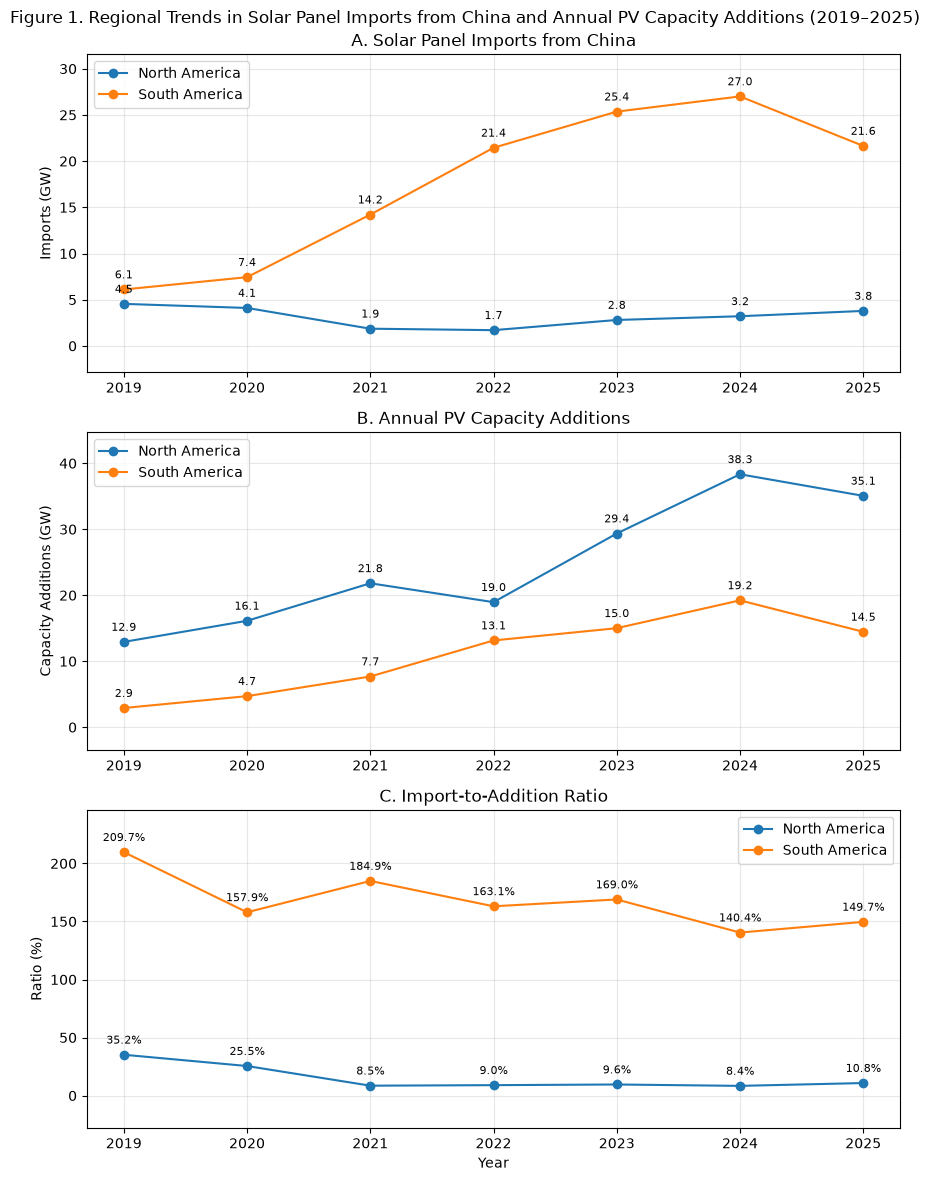

In [19]:
region = df.groupby(['Year', 'Study_scope'])[
    ['China_panel_exports_MW', 'PV_capacity_additions_MW']
].sum(min_count=1).reset_index()

# Calculate ratio
region['Ratio'] = (
    region['China_panel_exports_MW'] /
    region['PV_capacity_additions_MW'] * 100
)

# Remove 2018
region = region[region['Year'] >= 2019]

fig, axes = plt.subplots(3, 1, figsize=(9, 12))

for name, data in region.groupby('Study_scope'):
    axes[0].plot(data['Year'], 
                 data['China_panel_exports_MW'] / 1000,
                 marker='o', 
                 label=name)
    axes[1].plot(data['Year'], 
                 data['PV_capacity_additions_MW'] / 1000,
                 marker='o', 
                 label=name)
    axes[2].plot(data['Year'], 
                 data['Ratio'],
                 marker='o', 
                 label=name)

axes[0].set_title('A. Solar Panel Imports from China')
axes[0].set_ylabel('Imports (GW)')

axes[1].set_title('B. Annual PV Capacity Additions')
axes[1].set_ylabel('Capacity Additions (GW)')

axes[2].set_title('C. Import-to-Addition Ratio')
axes[2].set_ylabel('Ratio (%)')
axes[2].set_xlabel('Year')

# Add labels
for i, ax in enumerate(axes):
    for line in ax.get_lines():
        for x, y in zip(line.get_xdata(), line.get_ydata()):
            if pd.notna(y):
                label = f'{y:.1f}%' if i == 2 else f'{y:.1f}'
                ax.annotate(
                    label,
                    (x, y),
                    xytext=(0, 8),
                    textcoords='offset points',
                    ha='center',
                    fontsize=8
                )

    ax.margins(y=0.18)
    
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle(
    'Figure 1. Regional Trends in Solar Panel Imports from China and Annual PV Capacity Additions (2019–2025)'
)
plt.tight_layout()
plt.show()

* Figure 1 compares solar panel imports from China and PV capacity additions in North and South America. Regional totals can be strongly influenced by large countries, such as Brazil and the United States. 

# Change 2 (Lable with interactive)

In [20]:

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# ============================================================
# Change 2: Labels with Interactive Features
# Figure 1. Regional Trends in Solar Panel Imports from China
# and Annual PV Capacity Additions (2019–2025)
# ============================================================

# 1. Define colors for each region
colors = {
    'North America': '#EB6A50',
    'South America': '#2A9D8F'
}

# 2. Calculate regional totals
region = (
    df.groupby(['Year', 'Study_scope'])[
        ['China_panel_exports_MW', 'PV_capacity_additions_MW']
    ]
    .sum(min_count=1)
    .reset_index()
)

# 3. Filter years: 2019–2025
region = region.loc[
    region['Year'].between(2019, 2025)
].copy()

# 4. Sort data by region and year
region = region.sort_values(['Study_scope', 'Year'])

# 5. Convert MW to GW
region['Imports_GW'] = (
    region['China_panel_exports_MW'] / 1000
)

region['Additions_GW'] = (
    region['PV_capacity_additions_MW'] / 1000
)

# 6. Calculate import-to-addition ratio (%)
# Avoid division by zero
region['Ratio'] = np.where(
    region['PV_capacity_additions_MW'] > 0,
    (
        region['China_panel_exports_MW'] /
        region['PV_capacity_additions_MW']
    ) * 100,
    np.nan
)

# ============================================================
# 7. Create three subplots
# ============================================================

fig1 = make_subplots(
    rows=3,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.10,
    subplot_titles=[
        'A. Solar Panel Imports from China',
        'B. Annual PV Capacity Additions',
        'C. Import-to-Addition Ratio'
    ]
)

# ============================================================
# 8. Add interactive lines for each region
# ============================================================

for name, data in region.groupby('Study_scope'):

    # A. Imports from China
    fig1.add_trace(
        go.Scatter(
            x=data['Year'],
            y=data['Imports_GW'],
            mode='lines+markers',
            name=name,
            legendgroup=name,
            showlegend=True,

            line=dict(
                color=colors.get(name, '#808080'),
                width=3
            ),

            marker=dict(
                size=8
            ),

            hovertemplate=(
                f'<b>{name}</b><br>'
                'Year: %{x}<br>'
                'Imports from China: %{y:.2f} GW'
                '<extra></extra>'
            )
        ),
        row=1,
        col=1
    )

    # B. PV Capacity Additions
    fig1.add_trace(
        go.Scatter(
            x=data['Year'],
            y=data['Additions_GW'],
            mode='lines+markers',
            name=name,
            legendgroup=name,
            showlegend=False,

            line=dict(
                color=colors.get(name, '#808080'),
                width=3
            ),

            marker=dict(
                size=8
            ),

            hovertemplate=(
                f'<b>{name}</b><br>'
                'Year: %{x}<br>'
                'PV Capacity Additions: %{y:.2f} GW'
                '<extra></extra>'
            )
        ),
        row=2,
        col=1
    )

    # C. Import-to-Addition Ratio
    fig1.add_trace(
        go.Scatter(
            x=data['Year'],
            y=data['Ratio'],
            mode='lines+markers',
            name=name,
            legendgroup=name,
            showlegend=False,

            line=dict(
                color=colors.get(name, '#808080'),
                width=3
            ),

            marker=dict(
                size=8
            ),

            hovertemplate=(
                f'<b>{name}</b><br>'
                'Year: %{x}<br>'
                'Import-to-Addition Ratio: %{y:.1f}%'
                '<extra></extra>'
            )
        ),
        row=3,
        col=1
    )

# ============================================================
# 9. Axis labels
# ============================================================

fig1.update_yaxes(
    title_text='Imports (GW)',
    row=1,
    col=1
)

fig1.update_yaxes(
    title_text='Capacity Additions (GW)',
    row=2,
    col=1
)

fig1.update_yaxes(
    title_text='Ratio (%)',
    row=3,
    col=1
)

fig1.update_xaxes(
    title_text='Year',
    tickmode='linear',
    tick0=2019,
    dtick=1,
    row=3,
    col=1
)

# ============================================================
# 10. Layout and Interactive Features
# ============================================================

fig1.update_layout(
    title=(
        'Figure 1. Regional Trends in Solar Panel Imports '
        'from China and Annual PV Capacity Additions '
        '(2019–2025)'
    ),

    height=850,

    template='plotly_white',

    hovermode='closest',

    legend_title='Region',

    legend=dict(
        groupclick='togglegroup'
    ),

    margin=dict(
        l=80,
        r=40,
        t=100,
        b=60
    )
)

# ============================================================
# 11. Display figure
# ============================================================

fig1.show()


# ============================================================
# 12. Export Interactive Figure 1 as HTML
# ============================================================
from pathlib import Path
output_folder = Path.cwd().parent / "outputs"

output_folder.mkdir(parents=True, exist_ok=True)

#Save interactive HTML
output_path = output_folder / "Figure1_Regional_Trends.html"

fig1.write_html(
    str(output_path),
    include_plotlyjs=True
)

print("HTML saved to:", output_path.resolve())



HTML saved to: C:\ENV700\Solar Project\WangWangCheChen\outputs\Figure1_Regional_Trends.html


# Change 3 (Lable with interactive)

### Figure 2. Chinese Solar Panel Imports and PV Capacity Additions in 15 Countries (2019–2025)

In [21]:
import plotly.graph_objects as go
import plotly.express as px
import numpy as np

plot_df = df[df['Year'].between(2019, 2025)].copy()
countries = sorted(plot_df['Area'].unique())

fig = go.Figure()

def compress_y(y):
    y = np.asarray(y, dtype=float)

    return np.where(
        y <= 5,
        y,
        5 + (y - 5) / 5
    )

palette = (
    px.colors.qualitative.Plotly +
    px.colors.qualitative.Safe +
    px.colors.qualitative.Set3
)

country_colors = {
    country: palette[i % len(palette)]
    for i, country in enumerate(countries)
}


# Store real and compressed y-values
raw_y = []
compressed_y = []

# Actual data traces

for country in countries:

    d = plot_df[
        plot_df['Area'] == country
    ].sort_values('Year')

    imports = d['China_panel_exports_MW'] / 1000
    additions = d['PV_capacity_additions_MW'] / 1000

    raw_y.append(imports.to_numpy())
    compressed_y.append(compress_y(imports))

    raw_y.append(additions.to_numpy())
    compressed_y.append(compress_y(additions))


    # Imports from China

    fig.add_trace(go.Scatter(
        x=d['Year'],
        y=compress_y(imports),

        mode='lines+markers',

        showlegend=False,

        line=dict(
            color=country_colors[country],
            dash='solid',
            width=2.5
        ),

        marker=dict(
            color=country_colors[country],
            symbol='circle',
            size=8
        ),

        customdata=np.column_stack([
            [country] * len(d),
            imports
        ]),

        hovertemplate=(
            '<b>%{customdata[0]}</b><br>'
            'Year: %{x}<br>'
            'Imports from China: %{customdata[1]:.3f} GW'
            '<extra></extra>'
        )
    ))


    # PV Capacity Additions

    fig.add_trace(go.Scatter(
        x=d['Year'],
        y=compress_y(additions),

        mode='lines+markers',

        showlegend=False,

        line=dict(
            color=country_colors[country],
            dash='dot',
            width=2.5
        ),

        marker=dict(
            color=country_colors[country],
            symbol='square',
            size=8
        ),

        customdata=np.column_stack([
            [country] * len(d),
            additions
        ]),

        hovertemplate=(
            '<b>%{customdata[0]}</b><br>'
            'Year: %{x}<br>'
            'PV Capacity Additions: %{customdata[1]:.3f} GW'
            '<extra></extra>'
        )
    ))


# Country legend

for country in countries:

    fig.add_trace(go.Scatter(
        x=[None],
        y=[None],

        mode='lines+markers',

        name=country,

        line=dict(
            color=country_colors[country],
            width=2.5
        ),

        marker=dict(
            color=country_colors[country],
            size=8
        ),

        showlegend=True,
        legend='legend'
    ))


# Imports
fig.add_trace(go.Scatter(
    x=[None],
    y=[None],

    mode='lines+markers',

    name='Imports from China',

    line=dict(
        color='gray',
        dash='solid',
        width=2.5
    ),

    marker=dict(
        color='gray',
        symbol='circle',
        size=8
    ),

    showlegend=True,
    legend='legend2'
))


# PV Capacity Additions
fig.add_trace(go.Scatter(
    x=[None],
    y=[None],

    mode='lines+markers',

    name='PV Capacity Additions',

    line=dict(
        color='gray',
        dash='dot',
        width=2.5
    ),

    marker=dict(
        color='gray',
        symbol='square',
        size=8
    ),

    showlegend=True,
    legend='legend2'
))


n_data_traces = 2 * len(countries)

n_legend_traces = len(countries) + 2

legend_visibility = [True] * n_legend_traces


real_ticks = [
    0, 1, 2, 3, 4, 5,
    10, 20, 30, 40
]

compressed_ticks = compress_y(real_ticks)

buttons = []

# All Countries

buttons.append(
    dict(
        label='All Countries',

        method='update',

        args=[
            {
                'visible':
                    [True] * n_data_traces
                    + legend_visibility,

                'y':
                    compressed_y
                    + [[None]] * n_legend_traces
            },

            {
                'title':
                    'Solar Panel Imports from China and PV Capacity Additions: All Countries',

                'yaxis': {
                    'title':
                        'Capacity (GW, compressed scale)',

                    'tickmode':
                        'array',

                    'tickvals':
                        compressed_ticks,

                    'ticktext':
                        [str(x) for x in real_ticks],

                    'range':
                        [0, compress_y([40])[0] + 0.5]
                }
            }
        ]
    )
)


# Individual countries

for i, country in enumerate(countries):

    visible = [False] * n_data_traces

    visible[2 * i] = True
    visible[2 * i + 1] = True

    buttons.append(
        dict(
            label=country,

            method='update',

            args=[
                {
                    'visible':
                        visible
                        + legend_visibility,

                    'y':
                        raw_y
                        + [[None]] * n_legend_traces
                },

                {
                    'title':
                        f'Solar Panel Imports from China and PV Capacity Additions: {country}',

                    'yaxis': {
                        'title':
                            'Capacity (GW)',

                        'autorange':
                            True,

                        'tickmode':
                            'auto'
                    }
                }
            ]
        )
    )


# Layout

fig.update_layout(
    # title

    title=dict(
        text=(
            'Solar Panel Imports from China and '
            'PV Capacity Additions: All Countries'
        ),

        # Center the title
        x=0.5,
        xanchor='center',

        y=0.97,
        yanchor='top',

        font=dict(
            size=24
        )
    ),

    # X-axis

    xaxis=dict(

        title=dict(
            text='Year',
            font=dict(size=19)
        ),

        tickfont=dict(
            size=16
        )
    ),

    # Y-axis

    yaxis=dict(

        title=dict(
            text='Capacity (GW, compressed scale)',
            font=dict(size=19)
        ),

        tickfont=dict(
            size=16
        ),

        tickmode='array',

        tickvals=compressed_ticks,

        ticktext=[
            str(x) for x in real_ticks
        ],

        range=[
            0,
            compress_y([40])[0] + 0.5
        ]
    ),


    hovermode='closest',

    # Country selector

    updatemenus=[
        dict(
            buttons=buttons,

            direction='down',

            # Keep selector on upper-left,
            # below/away from title
            x=0.02,
            y=1.08,

            xanchor='left',
            yanchor='top',

            font=dict(
                size=15
            )
        )
    ],

    # Legend 1: Country colors

    legend=dict(

        title=dict(
            text='Country',
            font=dict(size=17)
        ),

        x=1.02,
        y=1,

        xanchor='left',
        yanchor='top',

        font=dict(
            size=14
        )
    ),

    # Legend 2: Measure

    legend2=dict(

        title=dict(
            text='Measure',
            font=dict(size=17)
        ),

        x=1.02,
        y=0.22,

        xanchor='left',
        yanchor='top',

        font=dict(
            size=14
        )
    ),

    # More room on top/right

    margin=dict(
        l=100,
        r=290,
        t=150,
        b=100
    ),


    height=700,
    annotations=[
        dict(
            x=1,
            y=-0.16,

            xref='paper',
            yref='paper',

            showarrow=False,

            xanchor='right',

            font=dict(
                size=13,
                color='gray'
            )
        )
    ]
)
fig.show()


# Export Interactive Figure 2 as HTML
from pathlib import Path

output_folder = Path.cwd().parent / "outputs"
output_folder.mkdir(parents=True, exist_ok=True)

output_path = output_folder / "Figure2_Country_Trends.html"

#Export interactive HTML
fig.write_html(
    str(output_path),
    include_plotlyjs=True
)

print("HTML saved to:", output_path.resolve())

HTML saved to: C:\ENV700\Solar Project\WangWangCheChen\outputs\Figure2_Country_Trends.html


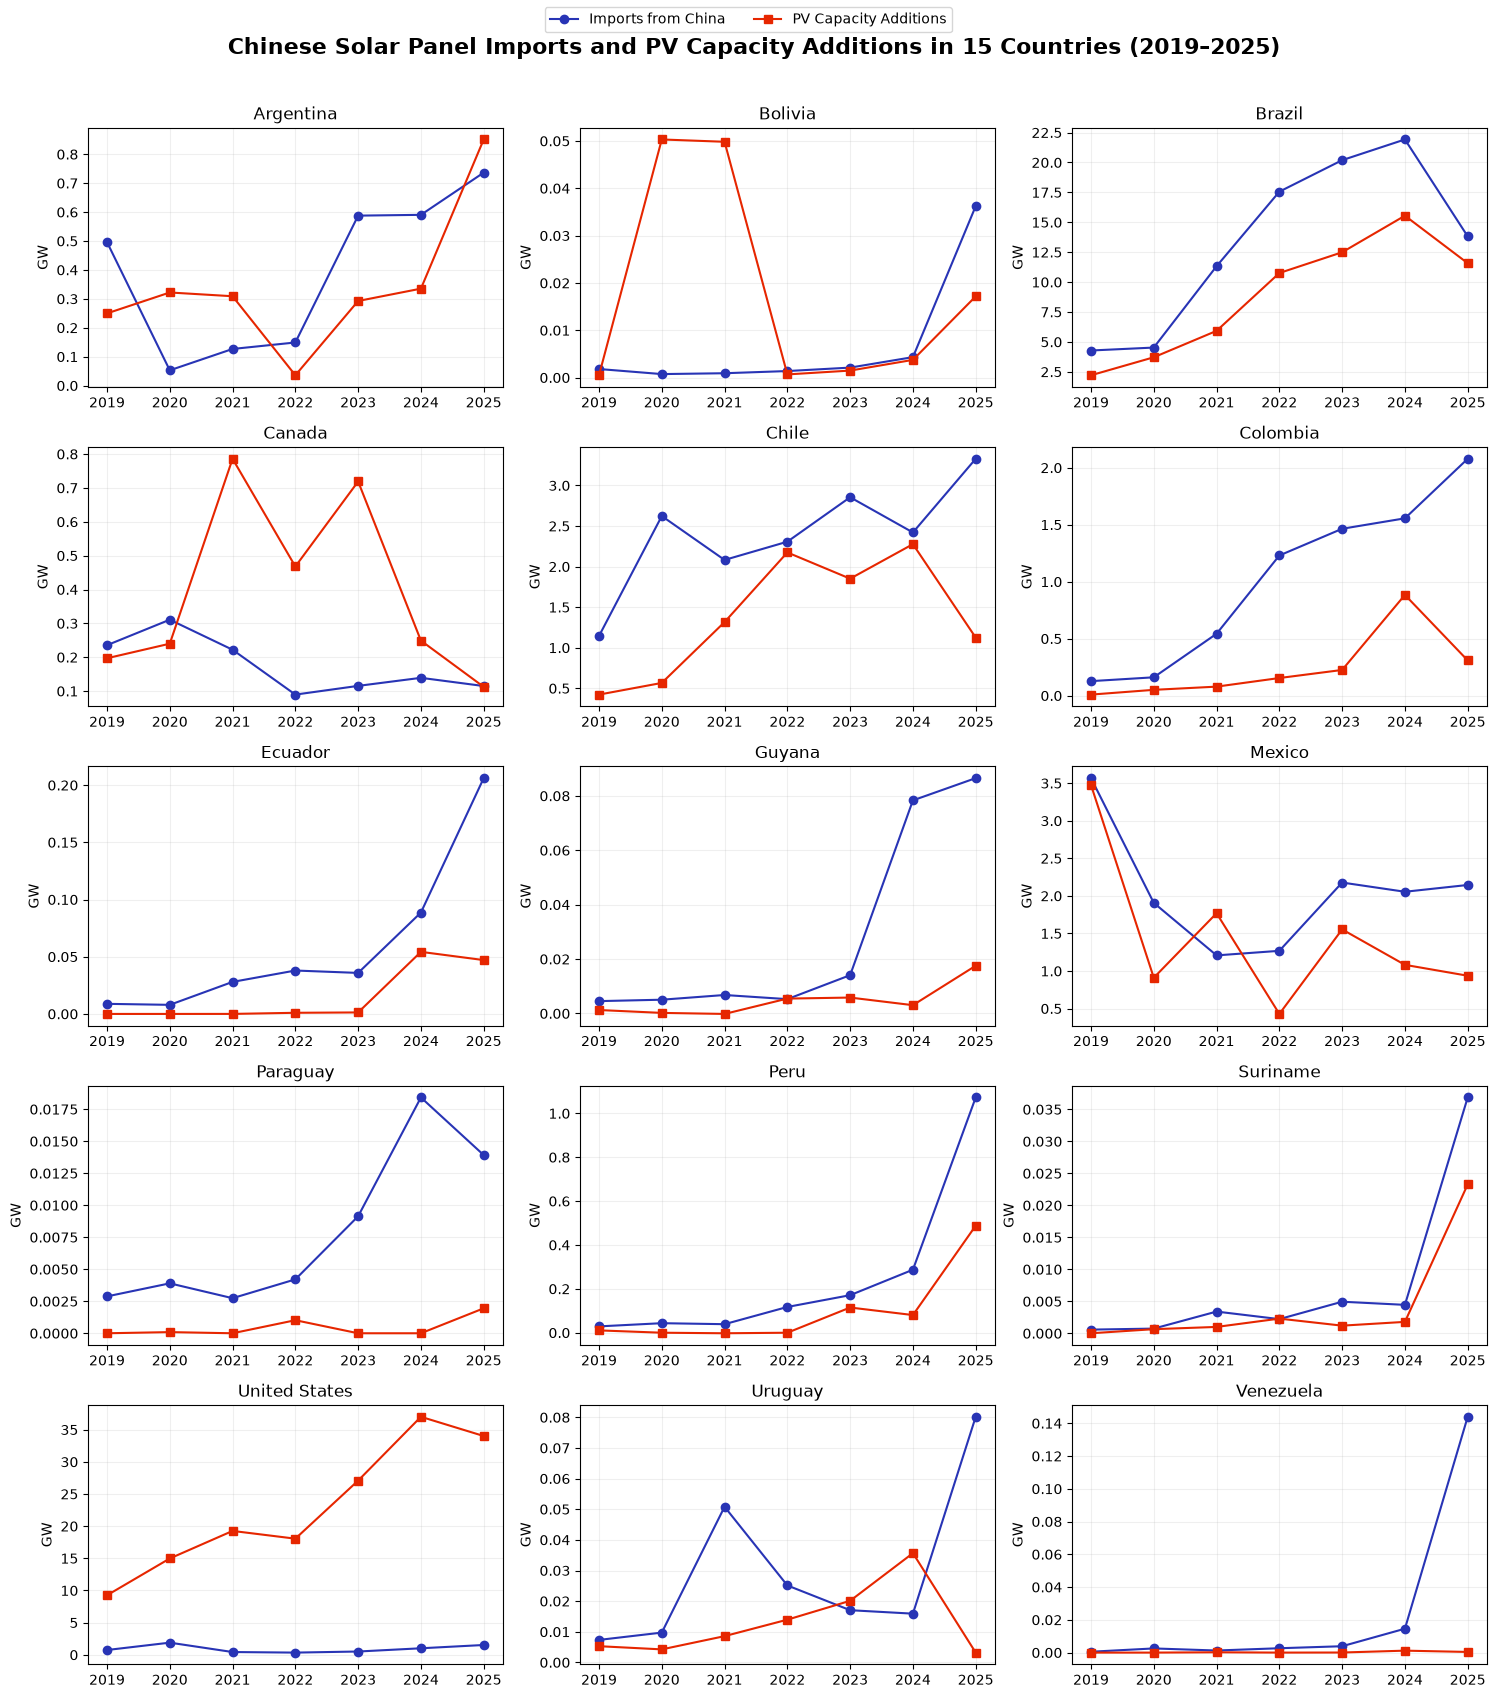

In [22]:
countries = sorted(df['Area'].unique())

fig, axes = plt.subplots(5, 3, figsize=(15, 17))
fig.suptitle(
    'Chinese Solar Panel Imports and PV Capacity Additions in 15 Countries (2019–2025)',
    fontsize=16,
    fontweight='bold'
)
for ax, country in zip(axes.flat, countries):
    data = df[(df['Area'] == country) & (df['Year'] >= 2019)]

    ax.plot(data['Year'], data['China_panel_exports_MW'] / 1000,
            marker='o', color="#2834B5", label='Imports from China')

    ax.plot(data['Year'], data['PV_capacity_additions_MW'] / 1000,
            marker='s', color="#E62600", label='PV Capacity Additions')

    ax.set_title(country)
    ax.set_ylabel('GW')
    ax.grid(alpha=0.2)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


* Figure 2 shows the trends for all 15 countries. Imports and capacity additions do not follow the same pattern. This may be related to installation delays, imports from other suppliers, or differences in local solar markets

### Figure 2 interactive dashboard

In [23]:
#Imports and settings
import argparse
from pathlib import Path

import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

FILENAME = "CLEANED_Study_area_data_2018_2025.csv"
START_YEAR, END_YEAR = 2019, 2025
YEARS = list(range(START_YEAR, END_YEAR + 1))

IMPORT_COLOR = "#598fcb"
ADDITION_COLOR = "#df923e"

try:
    SCRIPT_DIR = Path(__file__).resolve().parent
except NameError:
    SCRIPT_DIR = Path.cwd()

OUT_DIR = SCRIPT_DIR.parent / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)


#Load data
def find_csv(csv_arg=None):
    """Find the cleaned CSV whether you run from the repo root or the Scripts folder."""
    if csv_arg:
        p = Path(csv_arg).expanduser().resolve()
        if not p.is_file():
            raise FileNotFoundError(f"CSV file not found: {p}")
        return p
    candidates = [
        Path.cwd() / "data" / "Processed" / FILENAME,
        Path.cwd() / ".." / "data" / "Processed" / FILENAME,
        SCRIPT_DIR / ".." / "data" / "Processed" / FILENAME,
        SCRIPT_DIR / "data" / "Processed" / FILENAME,
        Path.cwd() / FILENAME,
        SCRIPT_DIR / FILENAME,
    ]
    for path in candidates:
        if path.is_file():
            return path.resolve()
    raise FileNotFoundError(
        f"Cannot find {FILENAME}. Pass its path using --csv.\nChecked:\n"
        + "\n".join(str(p.resolve()) for p in candidates)
    )


parser = argparse.ArgumentParser(description="Figure 2 interactive dashboard")
parser.add_argument("--csv", default=None, help="Path to the cleaned CSV file")
parser.add_argument("--out", default=str(OUT_DIR / "Figure2_Interactive_Dashboard.html"),
                    help="Output HTML path")
args, _ = parser.parse_known_args()

csv_path = find_csv(args.csv)
df = pd.read_csv(csv_path)
print(f"Loaded: {csv_path}")


#Clean and check data
expected = ["Area", "Year", "China_panel_exports_MW", "PV_capacity_additions_MW"]
missing = set(expected) - set(df.columns)
if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

d = df[expected].copy()
d["Year"] = pd.to_numeric(d["Year"], errors="raise").astype(int)
d = d[d["Year"].between(START_YEAR, END_YEAR)].copy()
if d.empty:
    raise ValueError(f"No observations from {START_YEAR} through {END_YEAR} found.")
if d.duplicated(["Area", "Year"]).any():
    raise ValueError("Duplicate Area-Year observations found: check data before plotting.")

for col in ["China_panel_exports_MW", "PV_capacity_additions_MW"]:
    d[col] = pd.to_numeric(d[col], errors="coerce")


d["Imports_GW"] = d["China_panel_exports_MW"] / 1000
d["Additions_GW"] = d["PV_capacity_additions_MW"] / 1000

countries = sorted(d["Area"].unique())
ALL_LABEL = f"All {len(countries)} countries"
print(f"Countries: {len(countries)}, years: {d['Year'].min()}–{d['Year'].max()}, rows: {len(d)}")


#Filter function
def filter_data(country="ALL", start=START_YEAR, end=END_YEAR, save_csv=False):
    """Return one row per year for a country (or the sum of all countries).

    country : "ALL" or a country name, e.g. "Brazil"
    start, end : year range (inclusive)
    save_csv : if True, also save the result to the outputs folder
    """
    sub = d if country == "ALL" else d[d["Area"] == country]
    if country != "ALL" and sub.empty:
        raise ValueError(f"Unknown country: {country}. Choose from: {countries}")

    table = (
        sub.groupby("Year")[["Imports_GW", "Additions_GW"]]
        .sum(min_count=1)
        .reindex(range(start, end + 1))
        .rename(columns={"Imports_GW": "Imports_from_China_GW",
                         "Additions_GW": "PV_Capacity_Additions_GW"})
    )
    table.index.name = "Year"

    if save_csv:
        name = "All15" if country == "ALL" else country.replace(" ", "_")
        path = OUT_DIR / f"Figure2_{name}_{start}-{end}.csv"
        table.to_csv(path, na_rep="")
        print(f"Saved: {path}")
    return table


print(filter_data("ALL").round(3))
print(filter_data("Brazil", 2021, 2024).round(3))


#Build the interactive figure
groups = ["ALL"] + countries
TRACES_PER_GROUP = 3

fig = make_subplots(
    rows=2, cols=1,
    row_heights=[0.66, 0.34],
    vertical_spacing=0.14,
    specs=[[{"type": "xy"}], [{"type": "table"}]],
)

for i, g in enumerate(groups):
    t = filter_data(g)
    show = (i == 0)

    fig.add_trace(go.Bar(
        x=t.index, y=t["Imports_from_China_GW"],
        name="Solar panel imports", marker_color=IMPORT_COLOR, width=0.48,
        visible=show,
        hovertemplate="Imports from China: %{y:.3f} GW<extra></extra>",
    ), row=1, col=1)

    fig.add_trace(go.Scatter(
        x=t.index, y=t["PV_Capacity_Additions_GW"],
        mode="lines+markers", name="PV capacity additions",
        line=dict(color=ADDITION_COLOR, width=3.5),
        marker=dict(color=ADDITION_COLOR, size=10, line=dict(color="#fff", width=1.5)),
        visible=show,
        hovertemplate="PV capacity additions: %{y:.3f} GW<extra></extra>",
    ), row=1, col=1)

    fmt = lambda s: ["NA" if pd.isna(v) else f"{v:.3f}" for v in s]
    fig.add_trace(go.Table(
        header=dict(values=["Year", "Imports from China (GW)", "PV Capacity Additions (GW)"],
                    fill_color="#f7f9fc", align=["left", "right", "right"]),
        cells=dict(values=[list(t.index), fmt(t["Imports_from_China_GW"]),
                           fmt(t["PV_Capacity_Additions_GW"])],
                   align=["left", "right", "right"]),
        visible=show,
    ), row=2, col=1)

#Country dropdown
country_buttons = []
for i, g in enumerate(groups):
    visible = [False] * (len(groups) * TRACES_PER_GROUP)
    for k in range(TRACES_PER_GROUP):
        visible[i * TRACES_PER_GROUP + k] = True
    label = ALL_LABEL if g == "ALL" else g
    subtitle = f"{ALL_LABEL} · annual totals" if g == "ALL" else f"{g} · annual values"
    country_buttons.append(dict(
        label=label, method="update",
        args=[{"visible": visible},
              {"title.text": f"Figure 2 — Imports vs. PV Capacity Additions<br><sup>{subtitle}</sup>"}],
    ))

#Year dropdown
year_ranges = [(START_YEAR, END_YEAR)] + [(y, y) for y in YEARS] + [
    (s, e) for s in YEARS for e in YEARS if e > s and (s, e) != (START_YEAR, END_YEAR)
]
year_buttons = [
    dict(label=str(s) if s == e else f"{s}–{e}", method="relayout",
         args=[{"xaxis.range": [s - 0.65, e + 0.65]}])
    for s, e in year_ranges
]

fig.update_layout(
    title=dict(text=f"Figure 2 — Imports vs. PV Capacity Additions<br><sup>{ALL_LABEL} · annual totals</sup>",
               x=0.0, xanchor="left", y=0.985, yanchor="top"),
    height=900,
    margin=dict(t=165, r=20, b=40, l=70),
    paper_bgcolor="#fff", plot_bgcolor="#fff",
    font=dict(family="Arial, sans-serif", color="#465064", size=13),
    hovermode="x unified",
    legend=dict(orientation="h", x=1.0, xanchor="right", y=1.10, yanchor="top"),
    updatemenus=[
        dict(buttons=country_buttons, direction="down", x=0.0, xanchor="left",
             y=1.11, yanchor="top", showactive=True),
        dict(buttons=year_buttons, direction="down", x=0.32, xanchor="left",
             y=1.11, yanchor="top", showactive=True),
    ],
    annotations=[
        dict(text="<b>Country</b>", x=0.0, y=1.15, xref="paper", yref="paper",
             showarrow=False, xanchor="left"),
        dict(text="<b>Year</b>", x=0.32, y=1.15, xref="paper", yref="paper",
             showarrow=False, xanchor="left"),
    ],
)
fig.update_xaxes(title_text="Year", tickmode="array", tickvals=YEARS,
                 range=[START_YEAR - 0.65, END_YEAR + 0.65],
                 showgrid=False, linecolor="#a6afbd", row=1, col=1)
fig.update_yaxes(title_text="Capacity (GW)", rangemode="tozero",
                 gridcolor="#e5eaf1", tickformat=",.2f", row=1, col=1)


#Save and show
out_path = Path(args.out)
out_path.parent.mkdir(parents=True, exist_ok=True)
fig.write_html(out_path, include_plotlyjs=True)   # True = works offline
print(f"Saved interactive dashboard: {out_path.resolve()}")
print("Units: GW (1 GW = 1,000 MW). All-country values are annual sums, not averages.")
print("Sources: Ember solar PV export data and IRENA installed capacity.")

fig.show()

Loaded: C:\ENV700\Solar Project\WangWangCheChen\data\Processed\CLEANED_Study_area_data_2018_2025.csv
Countries: 15, years: 2019–2025, rows: 105
      Imports_from_China_GW  PV_Capacity_Additions_GW
Year                                                 
2019                 10.656                    15.840
2020                 11.548                    20.839
2021                 16.076                    29.502
2022                 23.147                    32.102
2023                 28.166                    44.367
2024                 30.215                    57.564
2025                 25.431                    49.528
      Imports_from_China_GW  PV_Capacity_Additions_GW
Year                                                 
2021                 11.328                     5.924
2022                 17.561                    10.759
2023                 20.193                    12.495
2024                 21.924                    15.551
Saved interactive dashboard: C:\ENV700\Solar P

### Table 1. Annual Solar Panel Imports from China and PV Capacity Additions by Country and Region (2019–2025)

In [24]:
data = df[df['Year'].between(2019, 2025)].copy()

data['Imports (GW)'] = data['China_panel_exports_MW'] / 1000
data['Additions (GW)'] = data['PV_capacity_additions_MW'] / 1000

metrics = ['Imports (GW)', 'Additions (GW)']
years = list(range(2019, 2026))

columns = pd.MultiIndex.from_product(
    [years, metrics]
)

country = data.pivot(
    index=['Study_scope', 'Area'],
    columns='Year',
    values=metrics
)

country = country.swaplevel(0, 1, axis=1)
country = country.reindex(columns=columns)

region = data.groupby(['Study_scope', 'Year'])[metrics].sum(min_count=1)
region = region.unstack('Year')
region = region.swaplevel(0, 1, axis=1)
region = region.reindex(columns=columns)

rows = []

for area in ['North America', 'South America']:
    countries = country.loc[area].sort_index()
    rows.append(countries)

    regional_total = region.loc[[area]].copy()
    regional_total.index = [area + ' Total']
    rows.append(regional_total)

summary_table = pd.concat(rows).round(3)
summary_table.loc['All Countries Total'] = (
    summary_table.loc['North America Total']
    + summary_table.loc['South America Total']
)

display(summary_table.round(3))
summary_table.to_csv(
    'Table1_Imports_Additions_2019_2025.csv',
    na_rep=''
)


2019                        2020                 \
                    Imports (GW) Additions (GW) Imports (GW) Additions (GW)   
Canada                     0.236          0.197        0.311          0.240   
Mexico                     3.568          3.476        1.907          0.910   
United States              0.747          9.256        1.890         14.977   
North America Total        4.550         12.929        4.108         16.128   
Argentina                  0.496          0.250        0.053          0.322   
Bolivia                    0.002          0.000        0.001          0.050   
Brazil                     4.282          2.212        4.528          3.716   
Chile                      1.145          0.423        2.623          0.567   
Colombia                   0.127          0.009        0.161          0.051   
Ecuador                    0.009          0.000        0.008          0.000   
Guyana                     0.005          0.001        0.005          0.000   
Paraguay                   0.003          0.000        0.004          0.000   
Peru                       0.029          0.011        0.043          0.000   
Suriname                   0.001          0.000        0.001          0.001   
Uruguay                    0.007          0.005        0.010          0.004   
Venezuela                  0.001          0.000        0.003          0.000   
South America Total        6.106          2.911        7.440          4.711   
All Countries Total       10.656         15.840       11.548         20.839   

                            2021                        2022                 \
                    Imports (GW) Additions (GW) Imports (GW) Additions (GW)   
Canada                     0.222          0.786        0.090          0.468   
Mexico                     1.208          1.769        1.269          0.429   
United States              0.433         19.260        0.345         18.056   
North America Total        1.863         21.815        1.703         18.953   
Argentina                  0.127          0.309        0.149          0.036   
Bolivia                    0.001          0.050        0.001          0.001   
Brazil                    11.328          5.924       17.561         10.759   
Chile                      2.082          1.317        2.307          2.175   
Colombia                   0.543          0.079        1.230          0.155   
Ecuador                    0.028          0.000        0.038          0.001   
Guyana                     0.007         -0.000        0.005          0.005   
Paraguay                   0.003          0.000        0.004          0.001   
Peru                       0.039         -0.002        0.117         -0.000   
Suriname                   0.003          0.001        0.002          0.002   
Uruguay                    0.051          0.009        0.025          0.014   
Venezuela                  0.001          0.000        0.003          0.000   
South America Total       14.213          7.686       21.443         13.149   
All Countries Total       16.076         29.501       23.146         32.102   

                            2023                        2024                 \
                    Imports (GW) Additions (GW) Imports (GW) Additions (GW)   
Canada                     0.115          0.719        0.139          0.249   
Mexico                     2.178          1.554        2.055          1.082   
United States              0.514         27.085        1.016         37.005   
North America Total        2.807         29.358        3.210         38.336   
Argentina                  0.588          0.293        0.590          0.335   
Bolivia                    0.002          0.001        0.004          0.004   
Brazil                    20.193         12.495       21.924         15.551   
Chile                      2.855          1.852        2.421          2.277   
Colombia                   1.464          0.226        1.556          0.884 

* Table 1 summarizes annual imports and capacity additions for 15 countries. 

### Figure 3. Imports from China vs. PV Capacity Additions (2024)

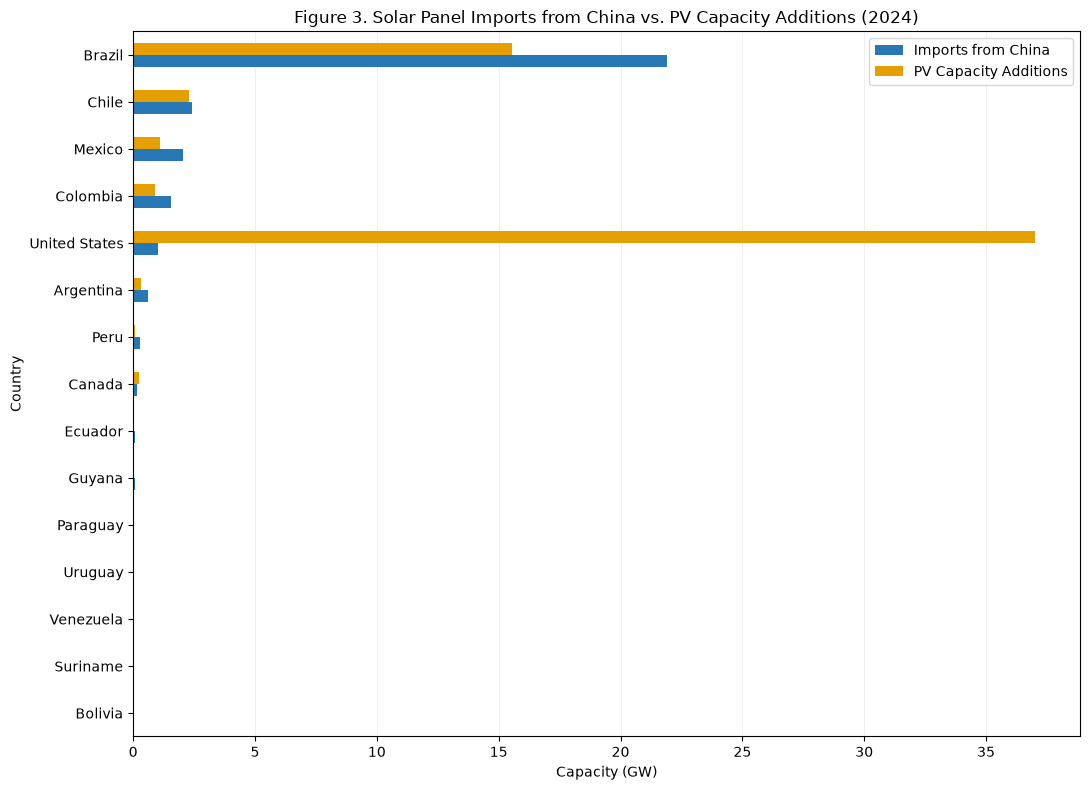

In [25]:
summary = df[df['Year'] == 2024].copy()

summary['Imports_GW'] = summary['China_panel_exports_MW'] / 1000
summary['Additions_GW'] = summary['PV_capacity_additions_MW'] / 1000

plot_data = summary.set_index('Area')[
    ['Imports_GW', 'Additions_GW']
]

plot_data = plot_data.sort_values('Imports_GW')

ax = plot_data.plot(
    kind='barh',
    figsize=(11, 8),
    color=['#2878B5', '#E69F00']
)

ax.set_xlabel('Capacity (GW)')
ax.set_ylabel('Country')
ax.set_title(
    'Figure 3. Solar Panel Imports from China vs. '
    'PV Capacity Additions (2024)'
)

ax.legend(['Imports from China', 'PV Capacity Additions'])
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


* Figure 3 compares imports and capacity additions across countries in 2024. Because 2024 provides a recent, consistent year for comparing the two measures.

* Imports from China and PV capacity additions show different patterns in different countries. This may be because panels are not installed right after being imported, and some countries also buy panels from other suppliers. The data do not include panel inventories, installation delays, or imports from other suppliers. So we plan to use correlation analysis to look more closely at the relationship.

### Dashboard for figure 3: Year-over-Year Changes in Solar PV

In [26]:
years = list(range(2020, 2026))
excluded = ["United States", "Brazil"]

#Keep a consistent country order across years
reference = df[df["Year"] == 2024].copy()
reference["Impact"] = reference["Export_change_GW"].abs() + reference["Addition_change_GW"].abs()
country_order = reference.sort_values("Impact", ascending=False)["Area"].tolist()
small_order = [c for c in country_order if c not in excluded]

#Create two side-by-side horizontal bar charts
fig = make_subplots(
    rows=1, cols=2, shared_yaxes=True, horizontal_spacing=0.08,
    subplot_titles=["Change in Chinese Panel Exports (GW)",
                    "Change in Annual PV Capacity Additions (GW)"]
)

#Store the plotting data for each view
all_x, all_y, all_colors = [], [], []
small_x, small_y, small_colors = [], [], []

for year in years:
    d = df[df["Year"] == year].set_index("Area").loc[country_order].reset_index()
    small = d[~d["Area"].isin(excluded)]

    for metric, color, light_color, col in [
        ("Export_change_GW", "#2563b4", "#a9c8e7", 1),
        ("Addition_change_GW", "#e17b18", "#f4c89a", 2),
    ]:
        colors = [color if c in excluded else light_color for c in d["Area"]]
        fig.add_trace(
            go.Bar(
                x=d[metric], y=d["Area"], orientation="h",
                marker_color=colors, visible=(year == 2024),
                hovertemplate=(f"<b>%{{y}}</b><br>{year-1} → {year}"
                               "<br>Change: %{x:+.3f} GW<extra></extra>")
            ), row=1, col=col
        )
        all_x.append(d[metric].tolist())
        all_y.append(d["Area"].tolist())
        all_colors.append(colors)
        small_x.append(small[metric].tolist())
        small_y.append(small["Area"].tolist())
        small_colors.append([light_color] * len(small))

#Year menu
year_buttons = []
for i, year in enumerate(years):
    visible = [False] * (2 * len(years))
    visible[2*i] = True
    visible[2*i+1] = True
    year_buttons.append(dict(
        label=str(year), method="update",
        args=[
            {"visible": visible},
            {"title.text": f"Figure 3. Solar PV Trade and Deployment Changes ({year-1} → {year})",
             "xaxis.autorange": True, "xaxis2.autorange": True}
        ]
    ))

#Country menu
view_buttons = [
    dict(label="All countries", method="update", args=[
        {"x": all_x, "y": all_y, "marker.color": all_colors},
        {"yaxis.categoryarray": country_order[::-1],
         "xaxis.autorange": True, "xaxis2.autorange": True}
    ]),
    dict(label="Exclude US & Brazil", method="update", args=[
        {"x": small_x, "y": small_y, "marker.color": small_colors},
        {"yaxis.categoryarray": small_order[::-1],
         "xaxis.autorange": True, "xaxis2.autorange": True}
    ])
]

#Layout
fig.update_layout(
    title=dict(text="Figure 3. Solar PV Trade and Deployment Changes (2023 → 2024)",
               x=0.02, xanchor="left", y=0.98),
    template="plotly_white", height=800,
    margin=dict(l=145, r=35, t=185, b=65),
    showlegend=False,
    updatemenus=[
        dict(buttons=year_buttons, active=years.index(2024),
             x=0.02, y=1.10, xanchor="left", yanchor="top", direction="down"),
        dict(buttons=view_buttons, active=0,
             x=0.30, y=1.10, xanchor="left", yanchor="top", direction="down"),
    ]
)
fig.add_annotation(text="<b>Year</b>", x=0.02, y=1.19, xref="paper", yref="paper",
                   xanchor="left", showarrow=False)
fig.add_annotation(text="<b>Country view</b>", x=0.30, y=1.19, xref="paper", yref="paper",
                   xanchor="left", showarrow=False)
fig.update_yaxes(categoryorder="array", categoryarray=country_order[::-1], row=1, col=1)
fig.update_yaxes(showticklabels=False, row=1, col=2)
fig.update_xaxes(title_text="Year-over-year change (GW)",
                 zeroline=True, zerolinecolor="gray", rangemode="normal")
fig.show()

#Export to project-root outputs folder
project_folder = csv_path.resolve().parent.parent.parent
output_folder = project_folder / "outputs"
output_folder.mkdir(exist_ok=True)
output_path = output_folder / "Figure3_Two_Dropdowns.html"
fig.write_html(str(output_path), include_plotlyjs=True)
print("Saved to:", output_path)


KeyError: 'Export_change_GW'